<a href="https://colab.research.google.com/github/Azi-Lizzy/ii-dlsca/blob/main/02_Multitask_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 2: Multi-Task Learning

In this exercise, you will explore how multi-task learning can make deep learning-based side-channel analysis (DL-SCA) more efficient. You will work with traces from a masked software implementation of AES and learn how to target all 16 key bytes using only one model.

The exercise consists of two steps:

- **Train and evaluate a single-task model:** Train a model using labels for the third byte of the targeted intermediate value. We call this model single-task because, following the divide-and-conquer strategy, it is trained to predict only one byte of a 16-byte intermediate value. Use this model’s predictions for the attack set to recover the corresponding key byte. Then investigate whether the same trained model can also recover other key bytes.

- **Explore and evaluate a multi-task model:** Use a model that predicts the targeted intermediate values for all 16 bytes to recover the full AES key, without training a separate model for each byte. You will explore how to adapt the single-task architecture and the guessing entropy (GE) calculation to support multiple tasks.

Compare the architectures of the single-task and multi-task models and examine how their predictions are used to calculate GE during the attack phase.

## Environment Preparations

Let’s start by setting up your Google Colab environment.

Run the cell below by clicking the ▶ button or pressing Shift + Enter. It installs the libraries needed for this exercise. Wait until the installation finishes before moving to the next cell.

You only need to run this installation once per Colab runtime session.

In [ ]:
!pip install numpy
!pip install h5py
!pip install trsfile
!pip install tensorflow==2.22.0rc0

## Download the dataset and the models

Next, download the nopoi-ASCAD dataset and pretrained models used in this exercise.

Run the cell below to download the files from Zenodo into your Colab environment. Wait until the download finishes before continuing.

You only need to run this cell once per Colab runtime session. The downloaded files and folders will be stored in /content/. You can find them by clicking the folder icon in Colab’s left sidebar.

In [ ]:
!wget https://zenodo.org/records/23102432/files/02_Multitask_Learning.zip?download=1 -O 02_Multitask_Learning.zip
!unzip 02_Multitask_Learning.zip
!rm 02_Multitask_Learning.zip

## Load the Dataset

Next, we load the dataset, which contains power consumption measurements from a masked software implementation of AES. The traces cover the first round of AES.

The original ASCAD-variable raw traces contain approximately one million samples per trace. To reduce the input size, we use the **noPOI** approach described in *Exploring Feature Selection Scenarios for Deep Learning-Based Side-Channel Analysis*. This approach averages consecutive samples within windows to produce shorter traces.

**Run the cell below** to load the dataset. For more information about the ASCAD dataset, see the [official ASCAD repository](https://github.com/ANSSI-FR/ASCAD).

In [2]:
import numpy as np
import h5py
from scipy import stats

AES_Sbox = np.array([
    0x63, 0x7C, 0x77, 0x7B, 0xF2, 0x6B, 0x6F, 0xC5, 0x30, 0x01, 0x67, 0x2B, 0xFE, 0xD7, 0xAB, 0x76,
    0xCA, 0x82, 0xC9, 0x7D, 0xFA, 0x59, 0x47, 0xF0, 0xAD, 0xD4, 0xA2, 0xAF, 0x9C, 0xA4, 0x72, 0xC0,
    0xB7, 0xFD, 0x93, 0x26, 0x36, 0x3F, 0xF7, 0xCC, 0x34, 0xA5, 0xE5, 0xF1, 0x71, 0xD8, 0x31, 0x15,
    0x04, 0xC7, 0x23, 0xC3, 0x18, 0x96, 0x05, 0x9A, 0x07, 0x12, 0x80, 0xE2, 0xEB, 0x27, 0xB2, 0x75,
    0x09, 0x83, 0x2C, 0x1A, 0x1B, 0x6E, 0x5A, 0xA0, 0x52, 0x3B, 0xD6, 0xB3, 0x29, 0xE3, 0x2F, 0x84,
    0x53, 0xD1, 0x00, 0xED, 0x20, 0xFC, 0xB1, 0x5B, 0x6A, 0xCB, 0xBE, 0x39, 0x4A, 0x4C, 0x58, 0xCF,
    0xD0, 0xEF, 0xAA, 0xFB, 0x43, 0x4D, 0x33, 0x85, 0x45, 0xF9, 0x02, 0x7F, 0x50, 0x3C, 0x9F, 0xA8,
    0x51, 0xA3, 0x40, 0x8F, 0x92, 0x9D, 0x38, 0xF5, 0xBC, 0xB6, 0xDA, 0x21, 0x10, 0xFF, 0xF3, 0xD2,
    0xCD, 0x0C, 0x13, 0xEC, 0x5F, 0x97, 0x44, 0x17, 0xC4, 0xA7, 0x7E, 0x3D, 0x64, 0x5D, 0x19, 0x73,
    0x60, 0x81, 0x4F, 0xDC, 0x22, 0x2A, 0x90, 0x88, 0x46, 0xEE, 0xB8, 0x14, 0xDE, 0x5E, 0x0B, 0xDB,
    0xE0, 0x32, 0x3A, 0x0A, 0x49, 0x06, 0x24, 0x5C, 0xC2, 0xD3, 0xAC, 0x62, 0x91, 0x95, 0xE4, 0x79,
    0xE7, 0xC8, 0x37, 0x6D, 0x8D, 0xD5, 0x4E, 0xA9, 0x6C, 0x56, 0xF4, 0xEA, 0x65, 0x7A, 0xAE, 0x08,
    0xBA, 0x78, 0x25, 0x2E, 0x1C, 0xA6, 0xB4, 0xC6, 0xE8, 0xDD, 0x74, 0x1F, 0x4B, 0xBD, 0x8B, 0x8A,
    0x70, 0x3E, 0xB5, 0x66, 0x48, 0x03, 0xF6, 0x0E, 0x61, 0x35, 0x57, 0xB9, 0x86, 0xC1, 0x1D, 0x9E,
    0xE1, 0xF8, 0x98, 0x11, 0x69, 0xD9, 0x8E, 0x94, 0x9B, 0x1E, 0x87, 0xE9, 0xCE, 0x55, 0x28, 0xDF,
    0x8C, 0xA1, 0x89, 0x0D, 0xBF, 0xE6, 0x42, 0x68, 0x41, 0x99, 0x2D, 0x0F, 0xB0, 0x54, 0xBB, 0x16
])


HW = np.array([int(i).bit_count() for i in range(256)], dtype=np.uint8)

def load_ascad_rand(dataset_file, num_bytes=16, profiling_traces=50000, attack_traces=10000):
    with h5py.File(dataset_file, "r") as dataset:
        # Load traces.
        X_profiling = dataset["Profiling_traces/traces"][:profiling_traces].astype(np.float32)
        X_attack = dataset["Attack_traces/traces"][:attack_traces].astype(np.float32)

        # Load metadata for the same traces.
        profiling_metadata = dataset["Profiling_traces/metadata"][:profiling_traces]
        attack_metadata = dataset["Attack_traces/metadata"][:attack_traces]

    # Extract plaintexts and keys.
    P_profiling = profiling_metadata["plaintext"].astype(np.uint8)
    K_profiling = profiling_metadata["key"].astype(np.uint8)

    P_attack = attack_metadata["plaintext"].astype(np.uint8)
    K_attack = attack_metadata["key"].astype(np.uint8)

    # Calculate first-round S-box outputs for the selected bytes.
    Y_profiling = HW[AES_Sbox[
        P_profiling[:, :num_bytes] ^ K_profiling[:, :num_bytes]
    ]]
    Y_attack = HW[AES_Sbox[
        P_attack[:, :num_bytes] ^ K_attack[:, :num_bytes]
    ]]

    print(f"Profiling traces shape: {X_profiling.shape}")
    print(f"Attack traces shape: {X_attack.shape}")

    return (
        (X_profiling, X_attack),
        (Y_profiling, Y_attack),
        (P_profiling, P_attack)
    )

dataset_file = '/mnt/d/Workshops/CHES_Tutorial/Data_base/02_Multitask_Learning/ascad-variable_nopoi_window_80.h5'
(X_profiling, X_attack), (Y_profiling, Y_attack), (plt_profiling, plt_attack) = load_ascad_rand(dataset_file)

Profiling traces shape: (50000, 6250)
Attack traces shape: (10000, 6250)


## Train and Evaluate a Single-Task Model

First, we will build and train a small model introduced in *Exploring Feature Selection Scenarios for Deep Learning-Based Side-Channel Analysis* for attacking the noPOI-preprocessed ASCAD dataset.

The model targets one key byte using the **identity (ID) leakage model**. The targeted intermediate value is the first-round AES S-box output:

$$
y_i = \mathrm{Sbox}\left(\mathrm{key}_i \oplus \mathrm{plt}_i\right)
$$

Here, $i \in \{0,\ldots,15\}$ is the byte index, $\mathrm{key}_i$ is the key byte, and $\mathrm{plt}_i$ is the corresponding plaintext byte.

With the ID leakage model, the label is the value of $y_i$, giving **256 possible classes**.

### Exercise: 
### Explore the model architecture

Look at the definition of `creat_single_task_model()`. This function builds a neural network reported in the literature to perform well when attacking the **third byte (byte index 2)** of the ASCAD dataset. Take a moment to understand the architecture and **draw a simple diagram** showing:

- The input shape.
- The type and order of all layers.
- The output shape.

You do not need to include every layer parameter. A clear sketch showing how data flows through the network is enough.

### Train and attack the third byte (byte index 2)

Use `model.fit()` to train the single-task model. If training takes too long, load the provided pretrained version of the same model. Do not forget to change `train_model` variable to False if you are using the pretrained model.

Next, use the model to predict class probabilities for the attack traces. Complete the missing code to calculate and plot the **guessing entropy (GE)** for the third key byte.  

In [3]:
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import *
from tensorflow.keras import backend as K
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import *


def creat_single_task_model(input_length, desync_level=5):
    tf.keras.utils.set_random_seed(929735)
    inputs = Input(shape=(input_length, 1))
    # This layer applies a random translation to the input data, which is a form of data augmentation.
    x = RandomTranslation(width_factor=desync_level/input_length, height_factor=0, fill_mode='wrap')(inputs)

    x = Conv1D(kernel_size=40, strides=20, filters=4, activation="selu", padding="same")(x)
    x = AveragePooling1D(pool_size=2, strides=2, padding="same")(x)
    x = BatchNormalization()(x)

    x = Conv1D(kernel_size=8, strides=4, filters=32, activation="selu", padding="same")(x)
    x = AveragePooling1D(pool_size=2, strides=2, padding="same")(x)
    x = BatchNormalization()(x)
    
    x = Flatten()(x)

    x = Dense(32, activation="selu", kernel_initializer="random_uniform")(x)
    x = Dense(32, activation="selu", kernel_initializer="random_uniform")(x)
    
    outputs = Dense(9, activation='softmax')(x)

    model = Model(inputs=inputs, outputs=outputs)

    model.compile(optimizer=Adam(), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    model.summary()
    return model


I0000 00:00:1791583507.434095   32863 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791583511.464242   32863 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791583597.972886   32863 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [ ]:
from sklearn.utils import shuffle
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

model_root = '/mnt/d/Workshops/CHES_Tutorial/Data_base/02_Multitask_Learning/Models/'
result_root = '/mnt/d/Datasets/ASCAD/Results/'

(X_profiling, X_attack), (Y_profiling, Y_attack), (plt_profiling, plt_attack) = load_ascad_rand(dataset_file)

aug_level = 5

epochs = 100
batch_size = 512
train_model = True

for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # The GPU may already be initialized if this cell is rerun.

target_byte = 2

num_attack_traces = 5000

# This is a pre-knowledge. you can check the accuracy by looking into the attack set key.
all_key = [0, 17, 34, 51, 68, 85, 102, 119, 136, 153, 170, 187, 204, 221, 238, 255]

HW = np.array([int(i).bit_count() for i in range(256)], dtype=np.uint8)

def calculate_ge(x_attack, plt_attack, log_probabilities, good_key, num_attack_traces, runs):
    n_attack = len(x_attack)
    leakage_model = "HW"  # ID or "HW"

    hypothesis_probabilities = np.zeros((n_attack, 256)) 

    for index in range(n_attack):
        for hypothesis in range(256):
            key = hypothesis

            if leakage_model == "ID":
              hypothesis_probabilities[index, hypothesis] = log_probabilities[
                  index, AES_Sbox[key^plt_attack[index]]]
            elif leakage_model == "HW":
              hypothesis_probabilities[index, hypothesis] = log_probabilities[
                  index, HW[ AES_Sbox[key^plt_attack[index]]]]


    # Accumulate scores and average the correct-key rank over repeated attacks.
    key_ranking_sum = np.zeros(num_attack_traces)
    for run in range(runs):
        shuffled_probabilities = shuffle(hypothesis_probabilities, random_state=0)
        key_probabilities = np.zeros(256)

        for index in range(num_attack_traces):
            key_probabilities += shuffled_probabilities[index]
            key_probabilities_sorted = np.argsort(key_probabilities)[::-1]

            correct_key_rank = list(key_probabilities_sorted).index(good_key) + 1
            key_ranking_sum[index] += correct_key_rank

    return key_ranking_sum / runs


# Normalize the data
scaler = StandardScaler()
X_profiling = scaler.fit_transform(X_profiling)
X_attack = scaler.transform(X_attack) 


# If model has Convolutional layers, we have to make the data dim equals to 3 
X_profiling = np.expand_dims(X_profiling, axis=-1)
X_attack = np.expand_dims(X_attack, axis=-1)

print("Creating the model!")
model = creat_single_task_model(X_attack.shape[1], desync_level=aug_level)

# Train the model
if train_model: 
    print("Training the model!")
    history = model.fit(X_profiling, 
                        Y_profiling[:, target_byte],
                        validation_split=0.15,
                        epochs=epochs, 
                        batch_size=batch_size, 
                        verbose=2)


    # model.save(model_root+"single_task_model.h5")

else:
    print('Loading the model!')
    model = load_model(model_root+"single_task_model.h5")

model.summary()   

# This is to make sure that data augmentation is not applied during the attack phase, we create a new model with desync_level=0
model_test = creat_single_task_model(X_attack.shape[1], desync_level=0)
model_test.set_weights(model.get_weights()) 

# Create an array of all possible bytes and their bit representations
all_bytes = np.arange(256)

# Calculate probabilities for each byte using broadcasting
log_probabilities = np.log(model_test.predict(X_attack))

guessing_entropy = calculate_ge(X_attack, plt_attack[:, target_byte], log_probabilities, all_key[target_byte], num_attack_traces, runs=50)

print(f'GE for byte {target_byte}: ', guessing_entropy[-1])
print("===============")

Profiling traces shape: (50000, 6250)
Attack traces shape: (10000, 6250)


W0000 00:00:1791583726.836987   32863 gpu_device.cc:2318] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


Creating the model!


W0000 00:00:1791583734.953318   32863 gpu_device.cc:2318] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1791583735.647519   32863 service.cc:154] XLA service 0x27352d40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791583735.647677   32863 service.cc:170]   StreamExecutor [0]: NVIDIA RTX PRO 4000 Blackwell Generation Laptop GPU, Compute Capability 12.0a (Driver: 13.2.0[596.53.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791583735.657050   32863 gpu_device.cc:1905] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13245 MB memory:  -> device: 0, name: NVIDIA RTX PRO 4000 Blackwell Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


Model: "functional"

...

 Total params: 23,229 (90.74 KB)

 Trainable params: 23,157 (90.46 KB)

 Non-trainable params: 72 (288.00 B)

Training the model!
Epoch 1/100


I0000 00:00:1791583758.610509   33678 cuda_dnn.cc:442] Loaded cuDNN version 92700


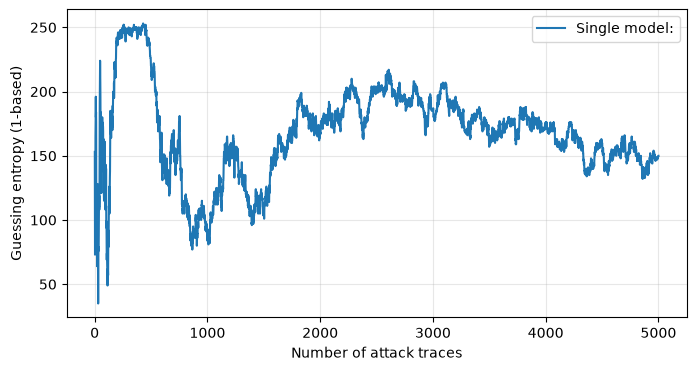

In [11]:
import matplotlib.pyplot as plt
trace_axis = np.arange(1, num_attack_traces + 1)
plt.figure(figsize=(8, 4))
plt.plot(trace_axis, guessing_entropy, label=f'Single model:')
plt.xlabel('Number of attack traces')
plt.ylabel('Guessing entropy (1-based)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Test Whether the Single-Task Model Can Attack the Other 15 Key Bytes

What we are about to do here is not the intended use of this model. The single-task model was trained specifically to predict the S-box output associated with the **third AES key byte (byte index 2)**.

However, we can intentionally apply the same model to the other key bytes to investigate if it gets any success in attacking other key bytes. Try to understand why the model succeeds or fails for the other bytes.


### Exercise: 

Without retraining the model, calculate and plot the GE for all 16 AES key bytes.

For each byte, make sure that you use the corresponding:

- plaintext byte,
- correct key byte,
- and S-box intermediate value.

Compare the final GE across the different key bytes and consider. 

- Does the model successfully attack any other bytes?
- How could you justify that considering the training process?


In [38]:
from sklearn.utils import shuffle
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

print('Loading the model!')
model = load_model(model_root+"single_task_model.h5")

# This is to make sure that data augmentation is not applied during the attack phase, we create a new model with desync_level=0
model_test = creat_single_task_model(X_attack.shape[1], desync_level=0)
model_test.set_weights(model.get_weights()) 

# Create an array of all possible bytes and their bit representations
all_bytes = np.arange(256)

for target_key_byte in range(16):

    # Calculate probabilities for each byte using broadcasting
    log_probabilities = np.log(model_test.predict(X_attack))

    guessing_entropy = calculate_ge(X_attack, plt_attack[:, target_key_byte], log_probabilities, all_key[target_key_byte], num_attack_traces, runs=50)

    print(f'GE for byte {target_key_byte}: ', guessing_entropy[-1])
    print("===============")

Loading the model!


Model: "functional_26"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_26 (InputLayer)     │ (None, 6250, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_26           │ (None, 6250, 1)        │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_52 (Conv1D)              │ (None, 313, 4)         │           164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling1d_52            │ (None, 157, 4)         │             0 │
│ (AveragePooling1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_52          │ (None, 157, 4)         │            16 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_53 (Conv1D)              │ (None, 40, 32)         │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling1d_53            │ (None, 20, 32)         │             0 │
│ (AveragePooling1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_53          │ (None, 20, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_26 (Flatten)            │ (None, 640)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_78 (Dense)                │ (None, 32)             │        20,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_79 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_80 (Dense)                │ (None, 256)            │         8,448 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,380 (122.58 KB)

 Trainable params: 31,308 (122.30 KB)

 Non-trainable params: 72 (288.00 B)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
GE for byte 0:  163.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
GE for byte 1:  253.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
GE for byte 2:  1.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
GE for byte 3:  50.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
GE for byte 4:  167.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
GE for byte 5:  213.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
GE for byte 6:  206.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
GE for byte 7:  113.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
GE for byte 8:  201.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
GE for byte 9:  47.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
GE for byte 10:  182.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
GE for byte 11:  254.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
GE for byte 12:  191.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
GE for byte 13:  33.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
GE for byte 14:  249.0
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
GE for byte 15

### Explore and evaluate a multi-task model

We will now use a **multi-task model** to attack all **16 AES key bytes** of the noPOI-preprocessed ASCAD dataset with a single neural network.

Training this multi-task model takes considerably longer than training the single-task model. If you are interested, you can later use the `fit()` function to train the model created by `creat_multi_task_model()` and verify the results yourself. For now, however, we will use a **pretrained multi-task model** with the same structure as the model created in `creat_multi_task_model()`.

### Exercise: 
### Explore the model architecture

Look at the definition of `creat_multi_task_model()`. This function builds a neural network that learns multiple tasks simultaneously.

Draw a simple diagram showing:

- The input shape.
- The type and order of the shared layers.
- The separate branches for each task.
- The output shape of each branch.

Compare your diagram with the single-task model. What has changed?

### Load the model and inspect its predictions

Load the pretrained multi-task model and use it to predict class probabilities for the attack traces.

Inspect the model outputs and consider:

- How many prediction outputs does the model return?
- What are the output classes for each branch?

#### Attack all 16 key bytes
Complete the missing code to calculate and plot the GE for all 16 key bytes.

For each key byte, make sure that you use:

- The predictions from the corresponding output branch.
- The corresponding plaintext byte.
- The correct key byte during the key rank.

Finally, compare the GE curves obtained with the **multi-task model** against those obtained previously using the **single-task model** for all 16 key bytes.

Consider:

- Does the multi-task model successfully attack all 16 key bytes?
- Which models result is better at key byte 3? What might explain that? 

In [39]:
def creat_multi_task_model(input_length, bin_num, desync_level=5):
    # Define the shared 1D CNN base model
    inputs = Input(shape=(input_length, 1))
    x = RandomTranslation(width_factor=desync_level/input_length, height_factor=0, fill_mode='wrap')(inputs)

    x = Conv1D(kernel_size=40, strides=20, filters=4, activation="selu", padding="same")(x)
    x = AveragePooling1D(pool_size=2, strides=2, padding="same")(x)
    x = BatchNormalization()(x)

    x = Conv1D(kernel_size=8, strides=4, filters=32, activation="selu", padding="same")(x)
    x = AveragePooling1D(pool_size=2, strides=2, padding="same")(x)
    x = BatchNormalization()(x)
    
    x = Flatten()(x)

    # Define separate MLPs for each task
    def create_mlp(input_layer):
        mlp = Dense(32, activation="selu", kernel_initializer="random_uniform")(input_layer)
        mlp = Dense(32, activation="selu", kernel_initializer="random_uniform")(mlp)
        return mlp

    # Define separate output layers for each task
    bit_outputs = [Dense(1, activation='sigmoid', name=f'bit{bin_num-1-i}')(create_mlp(x)) for i in range(bin_num)]

    # Combine the shared base model and output layers into a single Model
    model = Model(inputs=inputs, outputs=bit_outputs)

    # Compile the model with separate losses for each task
    model.compile(optimizer=Adam(), loss=['binary_crossentropy'] * bin_num, metrics=['accuracy']* bin_num)
    # model.summary()
    return model

In [41]:
# Axilary function 
# Converts a 2D array of integers into a 2D bit array.
def convert_2D_decimal_array_to_bits(arr):

    def decimal_to_binary(number, bits):
        return format(number, f'0{bits}b')

    arr = np.array(arr)
    max_values = np.max(arr, axis=0)
    result = []

    for row in arr:
        binary_row = []
        for idx, val in enumerate(row):
            binary_val = decimal_to_binary(val, 8)
            binary_row.extend([int(bit) for bit in binary_val])
        result.append(binary_row)
    
    return np.array(result)


# Axilary function that splits a (N, num_bits) bit array into a dict of per-bit label vectors keyed "bit{num_bits-1}", 
# for a multi-output model with one binary head per bit.
def get_multi_binary_model_label(data_bin):
    bin_num = data_bin.shape[1]
    return {f"bit{bin_num-i-1}": data_bin[:, i] for i in range(bin_num)}


# Axilary function that converts a byte value (0-255) into an array of its 8 bits.
def byte_to_bit_array(byte_val):
    return np.array([int(b) for b in format(byte_val, '08b')])

model_root = '/mnt/d/Workshops/CHES_Tutorial/Data_base/02_Multitask_Learning/Models/'

epochs = 200
batch_size = 512
train_model = False

Y_profiling_bin = convert_2D_decimal_array_to_bits(Y_profiling)
Y_attack_bin = convert_2D_decimal_array_to_bits(Y_attack)

bin_num = Y_profiling_bin.shape[1]

print("Creating the multi-task model!")
model = creat_multi_task_model(X_attack.shape[1], bin_num, desync_level=aug_level)

# Train the model
if train_model: 
    print('Training the multi-task model!')
    history = model.fit(X_profiling, 
                        get_multi_binary_model_label(Y_profiling_bin),
                        validation_split=0.15,
                        epochs=epochs, 
                        batch_size=batch_size, 
                        verbose=2)


    model.save(model_root+"multi_task_model.h5")

else:
    print('Loading the multi-task model!')
    model = load_model(model_root+"multi_task_model.h5")

model_test = creat_multi_task_model(X_attack.shape[1], bin_num, desync_level=0)
model_test.set_weights(model.get_weights()) 

# Calculate probabilities for each bit using the model
predictions = np.array(model_test.predict(X_attack))

# Create an array of all possible bytes and their bit representations
all_bytes = np.arange(256)
all_byte_bits = np.array([byte_to_bit_array(byte) for byte in all_bytes])

ge = np.zeros((16, num_attack_traces))

for target_key_byte in range(Y_profiling.shape[1]):
    print("Attack key byte {}".format(target_key_byte))
    byte_prob = np.ones((X_attack.shape[0], 256))
    for i in range(8):
        byte_prob *= all_byte_bits[:, i] * predictions[target_key_byte*8+i] + (1 - all_byte_bits[:, i]) * (1 - predictions[target_key_byte*8+i])

    ge[target_key_byte] = calculate_ge(X_attack, plt_attack[:, target_key_byte], byte_prob, all_key[target_key_byte], num_attack_traces, runs=50)

    print(f'GE for byte {target_key_byte}: ', ge[target_key_byte])
    print("===============")

K.clear_session()

Creating the multi-task model!
Loading the multi-task model!


313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step
Attack key byte 0
GE for byte 0:  [ 49. 110.  10. ...   1.   1.   1.]
Attack key byte 1
GE for byte 1:  [16. 38. 58. ...  1.  1.  1.]
Attack key byte 2
GE for byte 2:  [ 88. 155. 173. ...   1.   1.   1.]
Attack key byte 3


KeyboardInterrupt: 

**Note:** Although adapting the single-task model worked well in this exercise, this is not guaranteed for other models or datasets. Hyperparameter tuning remains important for finding an effective multi-task model.